## Setup

### Imports

In [1]:
import pandas as pd
import matplotlib as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

### Load and inspect

In [2]:
df = pd.read_csv('hair_health_dataset.csv')

print(df.head())
df.shape

  record_id  age  gender        ethnicity hair_type hair_texture hair_density  \
0   HH00001   21    Male         Hispanic     Curly       Medium       Medium   
1   HH00002   46  Female      Mixed_Other     Coily       Medium          Low   
2   HH00003   18    Male         Hispanic      Wavy       Coarse          Low   
3   HH00004   30    Male  African_Descent     Curly       Coarse       Medium   
4   HH00005   26  Female        Caucasian      Wavy       Medium       Medium   

  hair_fall_frequency hair_fall_level scalp_type  ... heat_styling_frequency  \
0               Daily            Mild     Normal  ...               Frequent   
1               Often            Mild        Dry  ...             Occasional   
2           Sometimes          Severe       Oily  ...             Occasional   
3           Sometimes        Moderate       Oily  ...               Frequent   
4              Rarely            Mild        Dry  ...                  Never   

  chemical_hair_treatment tight_

(2000, 38)

In [3]:
df.describe(
    include='all'
)

,record_id,age,gender,ethnicity,hair_type,hair_texture,hair_density,hair_fall_frequency,hair_fall_level,scalp_type,...,heat_styling_frequency,chemical_hair_treatment,tight_hairstyle_frequency,environmental_exposure,recent_significant_weight_loss,family_history,treatment_history,age_of_onset_years,hair_health_score,hair_loss_class
count,2000,2000.000000,2000,2000,2000,2000,2000,2000,2000,2000,...,2000,2000,2000,2000,2000,2000,2000,1264.000000,2000.000000,2000
unique,2000,NaN,3,6,4,3,3,4,3,4,...,4,5,3,3,2,2,7,NaN,NaN,4
top,HH00001,NaN,Female,Asian,Straight,Medium,Medium,Sometimes,Mild,Oily,...,Occasional,No_Chemical_Treatment,Never,Moderate,No,No,No_Treatment,NaN,NaN,Mild
freq,1,NaN,968,526,760,834,938,729,905,604,...,671,897,889,921,1734,1185,1024,NaN,NaN,928
mean,NaN,34.632000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.920886,69.173250,NaN
std,NaN,12.228792,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.084163,14.695988,NaN
min,NaN,15.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.000000,12.800000,NaN
25%,NaN,25.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.000000,59.675000,NaN
50%,NaN,34.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.000000,69.900000,NaN
75%,NaN,43.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39.000000,79.700000,NaN


## Data cleaning

### Missing values

In [4]:
missing_values = df.isnull().sum()

# only show columns with missing values
data_gap = missing_values.to_frame(name="missing count")
data_gap["missing percent"] = missing_values[missing_values > 0] / df.shape[0]

data_gap[data_gap["missing percent"] > 0]



,missing count,missing percent
age_of_onset_years,736,0.368


In [5]:
df[["age_of_onset_years", "hair_loss_class"]]


,age_of_onset_years,hair_loss_class
0,14.0,Mild
1,NaN,No_Hair_Loss
2,14.0,Moderate
3,27.0,Moderate
4,NaN,No_Hair_Loss
...,...,...
1995,NaN,No_Hair_Loss
1996,64.0,Mild
1997,32.0,Moderate
1998,NaN,No_Hair_Loss


`age_of_onset_years` is the age when hair loss started. It is null when `hair_loss_class` is `No_Hair_Loss`.

### Category values

Check the unique values of the columns for any abnormalities.

In [6]:
text_cols = df.select_dtypes(exclude="number").columns.drop("record_id")

for col in text_cols:
    print(col, df[col].unique())

gender <StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str
ethnicity <StringArray>
[       'Hispanic',     'Mixed_Other', 'African_Descent',       'Caucasian',
  'Middle_Eastern',           'Asian']
Length: 6, dtype: str
hair_type <StringArray>
['Curly', 'Coily', 'Wavy', 'Straight']
Length: 4, dtype: str
hair_texture <StringArray>
['Medium', 'Coarse', 'Fine']
Length: 3, dtype: str
hair_density <StringArray>
['Medium', 'Low', 'High']
Length: 3, dtype: str
hair_fall_frequency <StringArray>
['Daily', 'Often', 'Sometimes', 'Rarely']
Length: 4, dtype: str
hair_fall_level <StringArray>
['Mild', 'Severe', 'Moderate']
Length: 3, dtype: str
scalp_type <StringArray>
['Normal', 'Dry', 'Oily', 'Combination']
Length: 4, dtype: str
scalp_oiliness <StringArray>
['High', 'Low', 'Medium']
Length: 3, dtype: str
scalp_dryness <StringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: str
scalp_itching <StringArray>
['Mild', 'Severe', 'No_Itching', 'Moderate']
Length: 4, dtype: str
dandruff_pre

## Encoding

### One-hot encoding

Categories with no real order, where one value cannot be quantified as greater than another.

In [7]:
# non ordinal columns [to be one hot encoded]
non_ordinal_cols = ["gender", "ethnicity", "hair_type", "scalp_type", "dandruff_presence", "diet_type", "smoking_status","nutritional_deficiency", "medical_condition",  "life_stage_hormonal_event", "medication_affecting_hair", "chemical_hair_treatment", "recent_significant_weight_loss", "family_history", "treatment_history" ]

# one hot encode
encoded_df = pd.get_dummies(df, columns=non_ordinal_cols)

encoded_df.head()


,record_id,age,hair_texture,hair_density,hair_fall_frequency,hair_fall_level,scalp_oiliness,scalp_dryness,scalp_itching,wash_frequency_per_week,...,recent_significant_weight_loss_Yes,family_history_No,family_history_Yes,treatment_history_Ayurvedic_Home_Remedies,treatment_history_Finasteride,treatment_history_Hair_Transplant,treatment_history_Minoxidil,treatment_history_No_Treatment,treatment_history_Other,treatment_history_PRP_Therapy
0,HH00001,21,Medium,Medium,Daily,Mild,High,Medium,Mild,8,...,True,True,False,False,True,False,False,False,False,False
1,HH00002,46,Medium,Low,Often,Mild,Low,High,Severe,3,...,False,True,False,False,False,False,True,False,False,False
2,HH00003,18,Coarse,Low,Sometimes,Severe,Low,Low,No_Itching,3,...,False,False,True,False,False,False,False,False,True,False
3,HH00004,30,Coarse,Medium,Sometimes,Moderate,High,Low,Severe,1,...,False,False,True,False,False,False,False,True,False,False
4,HH00005,26,Medium,Medium,Rarely,Mild,Low,High,No_Itching,6,...,False,False,True,False,False,False,False,False,False,True


### Ordinal encoding

Asked AI to write this block because it was repetitive.

In [8]:
ordered = {
    "hair_texture": {"Fine": 0, "Medium": 1, "Coarse": 2},
    "hair_density": {"Low": 0, "Medium": 1, "High": 2},
    "hair_fall_frequency": {"Rarely": 0, "Sometimes": 1, "Often": 2, "Daily": 3},
    "hair_fall_level": {"Mild": 0, "Moderate": 1, "Severe": 2},
    "scalp_oiliness": {"Low": 0, "Medium": 1, "High": 2},
    "scalp_dryness": {"Low": 0, "Medium": 1, "High": 2},
    "scalp_itching": {"No_Itching": 0, "Mild": 1, "Moderate": 2, "Severe": 3},
    "stress_level": {"Low": 0, "Medium": 1, "High": 2},
    "alcohol_consumption": {"Non_Drinker": 0, "Occasional": 1, "Regular": 2},
    "heat_styling_frequency": {"Never": 0, "Occasional": 1, "Frequent": 2, "Daily": 3},
    "tight_hairstyle_frequency": {"Never": 0, "Occasional": 1, "Frequent": 2},
    "environmental_exposure": {"Low": 0, "Moderate": 1, "High": 2},
    "hair_loss_class": {"No_Hair_Loss": 0, "Mild": 1, "Moderate": 2, "Severe": 3},
}

encoded_df = encoded_df.replace(ordered).infer_objects()

## Exploratory analysis

### Correlation with the target

Top 10 positive and negative correlations with `hair_loss_class`.

In [9]:
hair_loss_class_corr = encoded_df.corr(numeric_only=True)["hair_loss_class"].sort_values(ascending=False)

print("top 11")
print(hair_loss_class_corr.head(11), "\n")

print("bottom 11")
print(hair_loss_class_corr.tail(11), "\n")

print("top 15 absolute values")
print(hair_loss_class_corr.abs().sort_values(ascending=False).head(15), "\n")

top 11
hair_loss_class                               1.000000
family_history_Yes                            0.462172
medical_condition_Alopecia_Areata             0.248825
age                                           0.240288
medication_affecting_hair_Yes_Chemotherapy    0.202799
age_of_onset_years                            0.176103
recent_significant_weight_loss_Yes            0.165175
smoking_status_Current                        0.143205
stress_level                                  0.141258
heat_styling_frequency                        0.120416
treatment_history_No_Treatment                0.114711
Name: hair_loss_class, dtype: float64 

bottom 11
treatment_history_Minoxidil                     -0.106486
dandruff_presence_No                            -0.109100
protein_frequency_per_week                      -0.119427
chemical_hair_treatment_No_Chemical_Treatment   -0.121502
smoking_status_Never                            -0.148780
recent_significant_weight_loss_No               

### Columns removed

Drop `hair_health_score` because it is a regressive result tied to the classification and can reveal the target, as noted by its high correlation and in the data dictionary.

Also drop `age_of_onset_years` because it is a perfect mapping of the no hair loss class. The rows stay: dropping them would remove the entire no hair loss class and 36% of the data.

In [10]:
encoded_df.drop(columns=["hair_health_score", "record_id", "age_of_onset_years"], inplace=True)

/var/folders/3d/s1n6wjb13fldk225bqnc484c0000gn/T/ipykernel_11001/2588489672.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  encoded_df.drop(columns=["hair_health_score", "record_id", "age_of_onset_years"], inplace=True)


### Relationships with the target

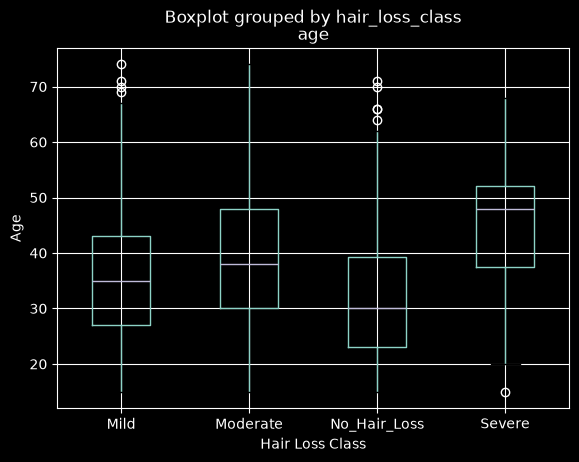

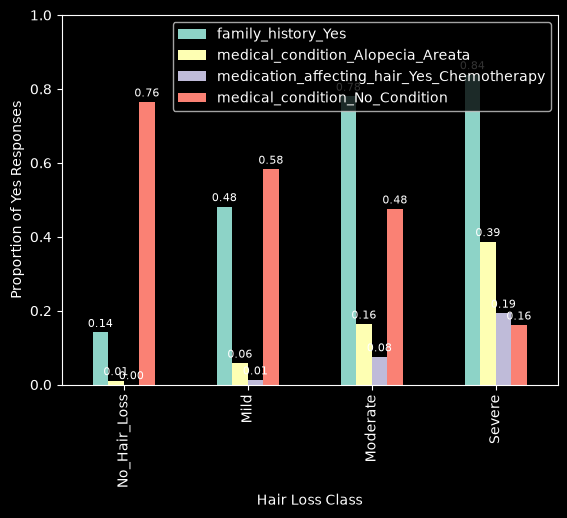

In [11]:
labels = {0: "No_Hair_Loss", 1: "Mild", 2: "Moderate", 3: "Severe"}

encoded_df.assign(hair_loss_class=encoded_df["hair_loss_class"].map(labels)).boxplot(
    column="age", by="hair_loss_class", xlabel="Hair Loss Class", ylabel="Age"
)

binary = [
    "family_history_Yes",
    "medical_condition_Alopecia_Areata",
    "medication_affecting_hair_Yes_Chemotherapy",
    "medical_condition_No_Condition"
]
rates = encoded_df.groupby("hair_loss_class")[binary].mean()
rates.index = rates.index.map(labels)
ax = rates.plot(kind="bar", xlabel="Hair Loss Class", ylabel="Proportion of Yes Responses", ylim=(0, 1))
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)


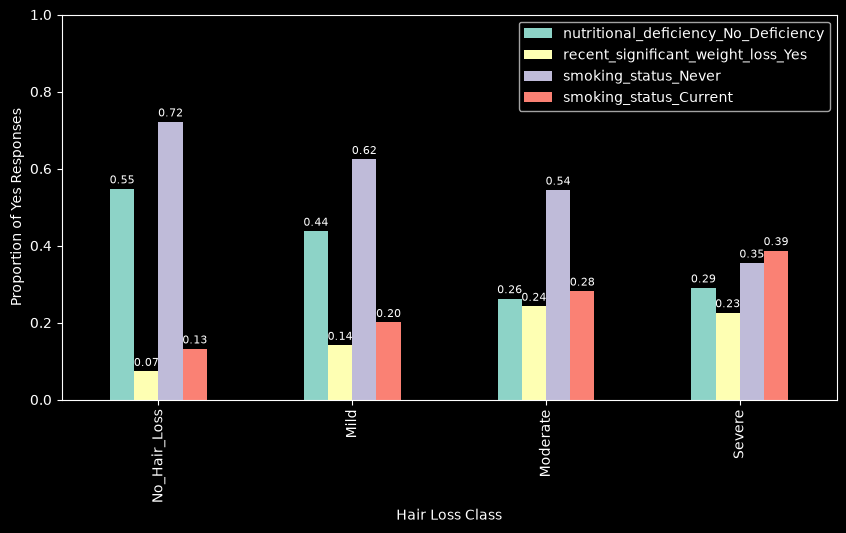

In [12]:
binary = [
    "nutritional_deficiency_No_Deficiency",
    "recent_significant_weight_loss_Yes",
    "smoking_status_Never",
    "smoking_status_Current"
]
rates = encoded_df.groupby("hair_loss_class")[binary].mean()
rates.index = rates.index.map(labels)
ax = rates.plot(
    kind="bar",
    xlabel="Hair Loss Class",
    ylabel="Proportion of Yes Responses",
    ylim=(0, 1),
    figsize=(10, 5),
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)



### Features to keep

Suggestion is to use `family_history_Yes`, `medical_condition_Alopecia_Areata`, `medical_condition_No_Condition`, `age`, and `smoking_status_Never`.

### Class balance

In [13]:
df["hair_loss_class"].value_counts()

hair_loss_class
Mild            928
No_Hair_Loss    736
Moderate        305
Severe           31
Name: count, dtype: int64

### Train-test split

In [14]:
train_df, test_df = train_test_split(encoded_df, test_size=0.2, random_state=42, stratify=encoded_df["hair_loss_class"])

X_train = train_df.drop(columns="hair_loss_class").astype(float)
y_train = train_df["hair_loss_class"]
X_test = test_df.drop(columns="hair_loss_class").astype(float)
y_test = test_df["hair_loss_class"]

### Modeling

Each model is built as a pipeline with three steps:
1. StandardScaler puts all features on the same scale, which matters for distance- and coefficient-based models.
2. SMOTE oversamples the minority classes ("Moderate" and "Severe") to balance the training data.
3. The model itself.

SMOTE is placed inside the pipeline so that it only runs on the training folds during cross-validation. If we applied it before cross-validation, synthetic copies of validation rows would leak into training and inflate the scores. The test set is never resampled.

We evaluate with 5-fold stratified cross-validation on the training set, then fit on the full training set and evaluate on the held-out test set. We use macro-F1 as the main metric because it weights all four classes equally, as opposed to accuracy which would be dominated by "No_Hair_Loss" and "Mild".


We compare four models of increasing complexity:
- Logistic Regression: a simple linear baseline. Its coefficients show how each feature pushes the prediction toward each class.
- K-Nearest Neighbours (KNN): classifies each person by the most common class among the most similar people in the training data. It makes no assumption about the shape of the relationship.
- Decision Tree: learns simple if/then rules (such as "family history = Yes and age > 40"). It captures interactions between features and is easy to interpret.
- Random Forest: an ensemble of many decision trees trained on random subsets of the data and features. It is usually more accurate and less prone to overfitting than a single tree.

### Logistic Regression

In [15]:
lr_smote = Pipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(max_iter=2000)),
])

cv = StratifiedKFold(5, shuffle=True, random_state=42)
scores = cross_val_score(lr_smote, X_train, y_train, cv=cv, scoring="f1_macro")
print(scores.mean())

lr_smote.fit(X_train, y_train)
print(classification_report(y_test, lr_smote.predict(X_test), target_names=["No_Hair_Loss", "Mild", "Moderate", "Severe"]))

0.5816999465239894
              precision    recall  f1-score   support

No_Hair_Loss       0.80      0.86      0.83       147
        Mild       0.81      0.68      0.74       186
    Moderate       0.56      0.64      0.60        61
      Severe       0.20      0.50      0.29         6

    accuracy                           0.74       400
   macro avg       0.59      0.67      0.61       400
weighted avg       0.76      0.74      0.75       400



#### **Interpretation**

We can see that for logistic regression, the two most represented classes ("No_Hair_Loss" and "Mild") have the best precision (0.80 & 0.81), recall (0.86 & 0.68) and F1-score (0.83 & 0.74).

However, the model does worse when it comes to the less represented classes ("Moderate" and "Severe"). For the "Moderate" class, precision is 0.56, meaning that the model is right a bit more than half the time, but with many false positives.

Meanwhile for the "Severe" class (most underrepresented) it catches 3 of the 6 "Severe" cases (recall 0.50), but precision is 0.20, so for 15 "Severe" predictions, about 12 were wrongly classified. With only 6 "Severe" cases in the test set, these numbers are very noisy.

On the plus side, CV macro-F1 of 0.58 vs. test macro-F1 of 0.61 means the model isn't overfitting, and the test result is believable.

### XGBoost

We select using five-fold stratified CV macro-F1 on training data, with scaling and SMOTE fitted inside each fold. The goal is better validation performance. The best CV score is a selection score and can be optimistic. These checks can indicate overfitting but cannot prove its absence.


In [16]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

xgb_smote = Pipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", XGBClassifier(
        # Keep the settings selected in the first search
        n_estimators=500,
        learning_rate=0.1,
        max_depth=2,
        objective="multi:softprob",
        num_class=4,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=4,
    )),
])

# Test stronger split restrictions and leaf-weight regularization
param_grid = {
    "model__min_child_weight": [1, 5, 10],
    "model__reg_lambda": [1, 5, 10],
}

xgb_search = GridSearchCV(
    xgb_smote,
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1,
)
xgb_search.fit(X_train, y_train)

print("Best parameters:", xgb_search.best_params_)
print("Best CV macro-F1:", xgb_search.best_score_)

# Compare all 9 regularization combinations
xgb_results = pd.DataFrame(xgb_search.cv_results_)
display(xgb_results[[
    "param_model__min_child_weight",
    "param_model__reg_lambda",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]].sort_values("rank_test_score"))



Best parameters: {'model__min_child_weight': 1, 'model__reg_lambda': 10}
Best CV macro-F1: 0.5298929259602819


,param_model__min_child_weight,param_model__reg_lambda,mean_test_score,std_test_score,rank_test_score
2,1,10,0.529893,0.047405,1
7,10,5,0.527338,0.053825,2
5,5,10,0.523254,0.045456,3
1,1,5,0.523244,0.043530,4
4,5,5,0.522423,0.045058,5
8,10,10,0.521072,0.051452,6
3,5,1,0.519687,0.050146,7
6,10,1,0.516820,0.053623,8
0,1,1,0.515405,0.037960,9


In [17]:
from sklearn.metrics import f1_score

# Reuse the completed grid search; no additional fitting is needed
xgb_best = xgb_search.best_estimator_
print("Selected parameters:", xgb_search.best_params_)
print("XGBoost best CV macro-F1 (selection score):", xgb_search.best_score_)
print("CV standard deviation:",
      xgb_search.cv_results_["std_test_score"][xgb_search.best_index_])
print("XGBoost train macro-F1:", f1_score(
    y_train, xgb_best.predict(X_train), average="macro"))
print("XGBoost test macro-F1:", f1_score(
    y_test, xgb_best.predict(X_test), average="macro"))
print(classification_report(
    y_test,
    xgb_best.predict(X_test),
    target_names=["No_Hair_Loss", "Mild", "Moderate", "Severe"],
    zero_division=0,
))


Selected parameters: {'model__min_child_weight': 1, 'model__reg_lambda': 10}
XGBoost best CV macro-F1 (selection score): 0.5298929259602819
CV standard deviation: 0.047404939917868115
XGBoost train macro-F1: 0.903224481321941
XGBoost test macro-F1: 0.5201855802193602
              precision    recall  f1-score   support

No_Hair_Loss       0.80      0.82      0.81       147
        Mild       0.71      0.77      0.74       186
    Moderate       0.62      0.46      0.53        61
      Severe       0.00      0.00      0.00         6

    accuracy                           0.73       400
   macro avg       0.53      0.51      0.52       400
weighted avg       0.72      0.73      0.72       400



#### **Interpretation**

We can see that XGBoost performs best on "No_Hair_Loss" and "Mild", with precision of 0.80 & 0.71, recall of 0.82 & 0.77, and F1-score of 0.81 & 0.74. It identifies most people in these common categories.

For "Moderate", precision is 0.62 but recall is only 0.46, meaning it catches about 28 of the 61 moderate cases and misses more than half. Logistic regression catches about 39. For "Severe", it correctly identifies none of the six cases, giving zero recall and F1. With only six severe test cases, this result is very noisy.

Test macro-F1 is 0.52 and accuracy is 0.73. This beats KNN, the decision tree, and the current random forest on macro-F1, but remains below logistic regression (0.61). The common classes support its accuracy, while missing Severe cases lowers its class-balanced score.

The selected model uses 500 rounds, depth 2, learning rate 0.1, and reg_lambda=10. Despite regularization, training macro-F1 of 0.90 is far above CV of 0.53 and test of 0.52, showing substantial overfitting. The similar CV and test scores do not remove that gap. XGBoost therefore adds complexity without improving our main metric over logistic regression.


### Logistic Regression with XGBoost (Stacking)

We combine the existing logistic regression pipeline with the optimal XGBoost configuration selected in a process called stacking. This clones and refits the above pipelines, using out-of-fold class probabilities to train the final logistic regression. It reuses the selected XGBoost settings instead of repeating the parameter grid inside each fold.

The stacking CV score is exploratory: XGBoost settings were selected using the same training data before this evaluation. The stack's internal out-of-fold predictions do not remove this parameter-selection bias. We report CV variability and compare training and held-out test macro-F1 for signs of overfitting. Do not use test results to select further settings.


In [18]:
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import f1_score

stacked_model = StackingClassifier(
    estimators=[
        ("lr", lr_smote),
        ("xgb", xgb_search.best_estimator_),
    ],
    final_estimator=LogisticRegression(max_iter=2000),
    stack_method="predict_proba",
    cv=cv,
)

stack_scores = cross_val_score(
    stacked_model, X_train, y_train, cv=cv, scoring="f1_macro"
)
print("Stacking CV macro-F1 (exploratory):", stack_scores.mean())
print("Standard deviation:", stack_scores.std())

stacked_model.fit(X_train, y_train)
print(classification_report(
    y_test,
    stacked_model.predict(X_test),
    target_names=["No_Hair_Loss", "Mild", "Moderate", "Severe"],
    zero_division=0,
))
# Compare training and held-out performance for signs of overfitting
print("Stacking train macro-F1:", f1_score(
    y_train, stacked_model.predict(X_train), average="macro"))
print("Stacking test macro-F1:", f1_score(
    y_test, stacked_model.predict(X_test), average="macro"))


Stacking CV macro-F1 (exploratory): 0.5408518492465606
Standard deviation: 0.013426515078524395
              precision    recall  f1-score   support

No_Hair_Loss       0.84      0.84      0.84       147
        Mild       0.78      0.79      0.78       186
    Moderate       0.67      0.69      0.68        61
      Severe       0.00      0.00      0.00         6

    accuracy                           0.78       400
   macro avg       0.57      0.58      0.58       400
weighted avg       0.77      0.78      0.78       400

Stacking train macro-F1: 0.6026630808306639
Stacking test macro-F1: 0.5755243302351011


#### **Interpretation**

We can see that stacking performs well on "No_Hair_Loss" and "Mild", with precision of 0.84 & 0.78, recall of 0.84 & 0.79, and F1-score of 0.84 & 0.78. Mild recall improves over logistic regression, catching about 147 of 186 cases instead of 126.

For "Moderate", precision is 0.67, recall is 0.69, and F1-score is 0.68. It catches about 42 of the 61 cases, compared with 39 for logistic regression and 28 for XGBoost. However, it misses all six "Severe" cases, while logistic regression catches three. This small severe sample makes the comparison uncertain.

Accuracy improves to 0.78, compared with 0.74 for logistic regression and 0.73 for XGBoost. However, test macro-F1 is 0.58, below logistic regression's 0.61. The stack improves common-class predictions but receives zero Severe F1, which has equal weight in macro-F1.

Training macro-F1 of 0.60 is closer to CV of 0.54 and test of 0.58, suggesting less apparent overfitting than XGBoost. This is not proof, and CV remains exploratory because XGBoost settings were selected beforehand on the same training data. Stacking improves overall accuracy and Moderate detection, but logistic regression remains stronger on our class-balanced metric.


### K-Nearest Neighbours (KNN)

In [19]:
knn_smote = Pipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", KNeighborsClassifier(n_neighbors=5)),
])

scores = cross_val_score(knn_smote, X_train, y_train, cv=cv, scoring="f1_macro")
print(scores.mean())

knn_smote.fit(X_train, y_train)
print(classification_report(y_test, knn_smote.predict(X_test), target_names=["No_Hair_Loss", "Mild", "Moderate", "Severe"]))

0.3184529727799839
              precision    recall  f1-score   support

No_Hair_Loss       0.55      0.84      0.66       147
        Mild       0.60      0.15      0.23       186
    Moderate       0.33      0.57      0.42        61
      Severe       0.04      0.17      0.06         6

    accuracy                           0.47       400
   macro avg       0.38      0.43      0.35       400
weighted avg       0.53      0.47      0.42       400



x#### **Interpretation**

We can see that for KNN, performance is much worse than logistic regression across almost every class.

The "No_Hair_Loss" class does best, with high recall (0.84) but only moderate precision (0.55), so the model over-predicts "No_Hair_Loss".

The "Mild" class (the most represented) is where KNN struggles most: precision is 0.60, but recall is only 0.15, meaning it catches about 28 of the 186 "Mild" cases and labels the rest as other classes.

For the "Moderate" class, recall is 0.57 but precision is 0.33, meaning that the model is right only about a third of the time when it predicts "Moderate", with many false positives.

Meanwhile for the "Severe" class (most underrepresented) it catches 1 of the 6 "Severe" cases (recall 0.17), and precision is 0.04, so for about 25 "Severe" predictions, about 24 were wrongly classified. With only 6 "Severe" cases in the test set, these numbers are very noisy.

CV macro-F1 of 0.32 vs. test macro-F1 of 0.35 means the model is consistent, so the poor result is not due to a bad split, KNN simply fits this data poorly. Likely reasons are that distances become less meaningful with around 88 mostly binary features, and that SMOTE's synthetic points pull predictions away from the "Mild" class toward the minority classes.

### Decision Tree

A tree with no depth limit keeps splitting until it memorizes the training data, which would perform poorly on the test set, so we first compare a few maximum depths with cross-validation and keep the best one.

In [20]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

for depth in [2, 3, 4, 5, 6, 7, 8, 10, None]:
    dt = Pipeline([
        ("scale", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", DecisionTreeClassifier(max_depth=depth, random_state=42)),
    ])
    print(depth, cross_val_score(dt, X_train, y_train, cv=cv, scoring="f1_macro").mean())

2 0.32384128262857875
3 0.4277853864215116
4 0.4235491849623821
5 0.434453232866964
6 0.44291028393741205
7 0.43922220345036517
8 0.43696553804319
10 0.421417467259446
None 0.43076804861688067


We can see that having a depth of 6 gives us the best f1-macro (0.44) before it starts going down. With no depth limit, it ends up memorizing the training set and still performs poorly at CV f1-macro=0.43.

In [21]:
dt_smote = Pipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", DecisionTreeClassifier(max_depth=6, random_state=42)),
])

scores = cross_val_score(dt_smote, X_train, y_train, cv=cv, scoring="f1_macro")
print("CV macro-F1:", scores.mean())
print("Standard deviation: ", scores.std())

dt_smote.fit(X_train, y_train)
print("train macro-F1:", f1_score(y_train, dt_smote.predict(X_train), average="macro"))
print(classification_report(y_test, dt_smote.predict(X_test), target_names=["No_Hair_Loss", "Mild", "Moderate", "Severe"], zero_division=0))

CV macro-F1: 0.44291028393741205
Standard deviation:  0.04345746423620071
train macro-F1: 0.6251988679540573
              precision    recall  f1-score   support

No_Hair_Loss       0.65      0.69      0.67       147
        Mild       0.57      0.56      0.56       186
    Moderate       0.40      0.31      0.35        61
      Severe       0.00      0.00      0.00         6

    accuracy                           0.56       400
   macro avg       0.40      0.39      0.39       400
weighted avg       0.56      0.56      0.56       400



|--- family_history_No <= 0.83
|   |--- medical_condition_No_Condition <= 0.77
|   |   |--- smoking_status_Current <= -0.47
|   |   |   |--- truncated branch of depth 4
|   |   |--- smoking_status_Current >  -0.47
|   |   |   |--- truncated branch of depth 4
|   |--- medical_condition_No_Condition >  0.77
|   |   |--- nutritional_deficiency_No_Deficiency <= 1.10
|   |   |   |--- truncated branch of depth 4
|   |   |--- nutritional_deficiency_No_Deficiency >  1.10
|   |   |   |--- truncated branch of depth 4
|--- family_history_No >  0.83
|   |--- medical_condition_No_Condition <= -1.20
|   |   |--- medical_condition_Alopecia_Areata <= -0.25
|   |   |   |--- truncated branch of depth 4
|   |   |--- medical_condition_Alopecia_Areata >  -0.25
|   |   |   |--- truncated branch of depth 4
|   |--- medical_condition_No_Condition >  -1.20
|   |   |--- medication_affecting_hair_No <= -1.65
|   |   |   |--- truncated branch of depth 4
|   |   |--- medication_affecting_hair_No >  -1.65
|   |   |

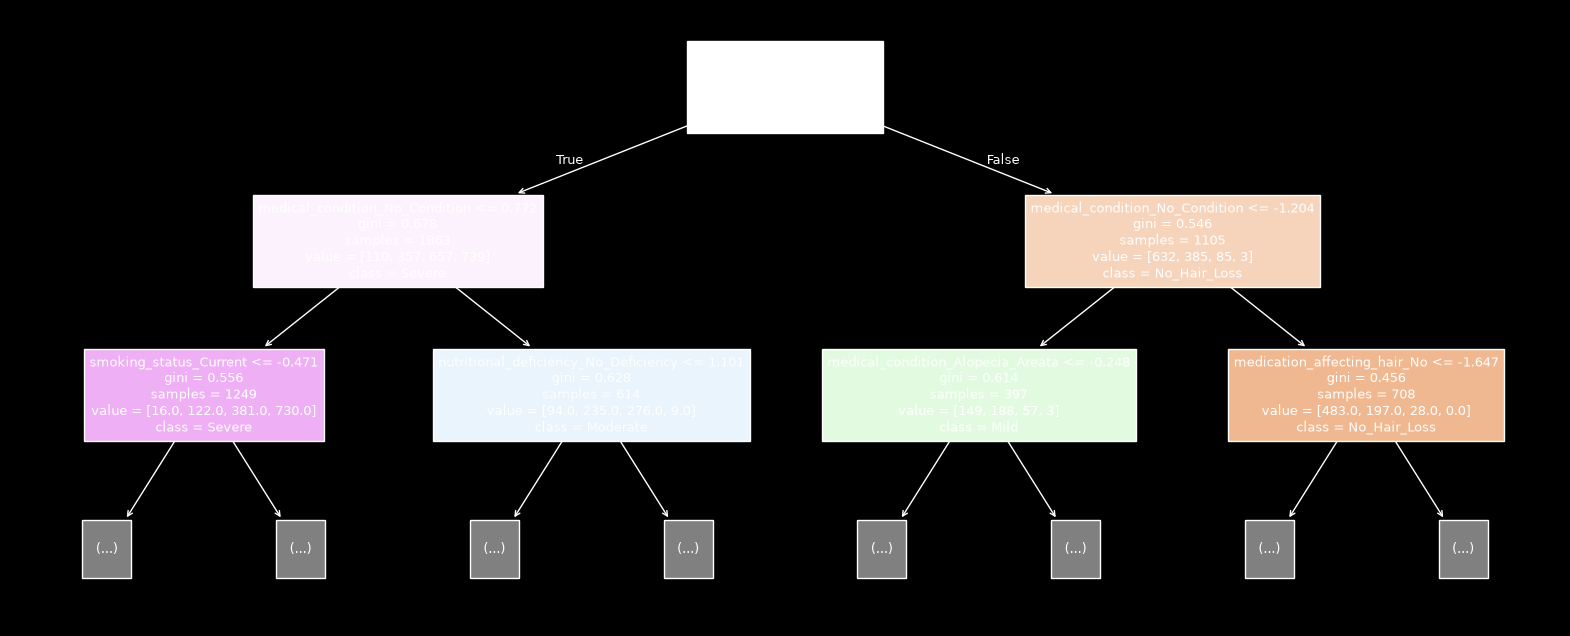

In [22]:
tree = dt_smote.named_steps["model"]

# show first 2 levels of splits of the tree
print(export_text(tree, feature_names=list(X_train.columns), max_depth=2))

# top 10 feature importances
print(pd.Series(tree.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10))

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree, feature_names=list(X_train.columns), class_names=["No_Hair_Loss", "Mild", "Moderate", "Severe"], max_depth=2, filled=True, fontsize=9, ax=ax)
plt.show()

#### **Interpretation**

The depth comparison shows that every depth from 3 to unlimited (`None`) lands at a CV macro-F1 of about 0.42–0.44, so limiting the depth stops the tree from memorizing the training data but does not make it more accurate. We keep `max_depth=6`, which scored highest.

We can see that for the decision tree, performance is better than KNN but much worse than logistic regression (test macro-F1 0.39 vs. 0.61, accuracy 0.56 vs. 0.74).

The two most represented classes ("No_Hair_Loss" and "Mild") do best, with precision of 0.65 & 0.57 and recall of 0.69 & 0.56, but both are well below logistic regression. For the "Moderate" class, recall is 0.31, meaning it catches only about 19 of the 61 "Moderate" cases, and precision is 0.40, so most of its "Moderate" predictions are wrong.

For the "Severe" class it catches none of the 6 cases. Part of the reason is SMOTE: the training set has only 25 (31 total - 6 in test set) real "Severe" rows, so about 717 (742 - 25) of the 742 (largest class "Mild" 928 - 186 "Mild" in test set = 742 balanced after SMOTE) "Severe" rows the tree learns from are synthetic. The tree learns "Severe" rules from synthetic data that do not match the real ones.

The training macro-F1 (0.63) is well above the CV macro-F1 (0.44), so the tree still overfits  even at depth 6. The test macro-F1 (0.39) is a little below CV, which is within the normal fold-to-fold variation. The main strength of the tree is that its rules can be read, for example, the first split is family history: people with a family history go left toward "Moderate"/"Severe", people without go right toward "No_Hair_Loss".

The feature importances agree with the rules: family history (0.27), no medical condition (0.18), current smoker (0.11), age (0.09) and nutritional deficiency (0.06) make up about 70% of the total, and most of the features are barely used. These are similar drivers found in the correlation analysis and in the features to keep. Unlike logistic regression coefficients, importance shows how much a feature is used but not which direction it pushes, it doesn't tell if it leads to more or less hair loss, so the rules are needed for direction.

Overall, the tree gives an easy-to-explain risk path, but its blunt cut-offs make it much less accurate than logistic regression, especially for the "Moderate" and "Severe" classes.

### Random Forest

We select the highest mean five-fold CV macro-F1 using training data only. Scaling and SMOTE remain inside each fold. We report CV variability and training/test macro-F1; a smaller gap is useful only if validation performance remains competitive. The best grid score is potentially optimistic, and the already-inspected test set provides only an exploratory follow-up check. Too much restriction may underfit, so improvement is not guaranteed.


In [23]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

rf_smote = Pipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
])

# Restrict individual trees while keeping 300 trees in the forest to limit overfitting
rf_param_grid = {
    "model__max_depth": [4, 6, 10],
    "model__min_samples_leaf": [1, 5, 10],
}
rf_search = GridSearchCV(
    rf_smote,
    rf_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1,
)
rf_search.fit(X_train, y_train)

print("Best parameters:", rf_search.best_params_)
print("RF best CV macro-F1 (selection score):", rf_search.best_score_)
print("Standard deviation:",
      rf_search.cv_results_["std_test_score"][rf_search.best_index_])

rf_results = pd.DataFrame(rf_search.cv_results_)
display(rf_results[[
    "param_model__max_depth",
    "param_model__min_samples_leaf",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]].sort_values("rank_test_score"))

# Keep the existing variable name for the feature-importance code below
rf_smote = rf_search.best_estimator_
print("RF train macro-F1:", f1_score(
    y_train, rf_smote.predict(X_train), average="macro"))
print("RF test macro-F1:", f1_score(
    y_test, rf_smote.predict(X_test), average="macro"))
print(classification_report(
    y_test,
    rf_smote.predict(X_test),
    target_names=["No_Hair_Loss", "Mild", "Moderate", "Severe"],
    zero_division=0,
))


Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 10}
RF best CV macro-F1 (selection score): 0.49939490263579156
Standard deviation: 0.07896328209390258


,param_model__max_depth,param_model__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
8,10,10,0.499395,0.078963,1
7,10,5,0.468423,0.030003,2
4,6,5,0.467780,0.061827,3
6,10,1,0.463186,0.015007,4
5,6,10,0.460517,0.056667,5
3,6,1,0.459423,0.042164,6
1,4,5,0.418349,0.046188,7
0,4,1,0.411027,0.037702,8
2,4,10,0.409575,0.032310,9


RF train macro-F1: 0.8491527763410602
RF test macro-F1: 0.4248626128324423
              precision    recall  f1-score   support

No_Hair_Loss       0.62      0.84      0.71       147
        Mild       0.60      0.45      0.52       186
    Moderate       0.47      0.48      0.47        61
      Severe       0.00      0.00      0.00         6

    accuracy                           0.59       400
   macro avg       0.42      0.44      0.42       400
weighted avg       0.58      0.59      0.57       400



In [24]:
importance = pd.Series(rf_smote.named_steps["model"].feature_importances_, index=X_train.columns)
print("Importance per one-hot column:")
print(importance.sort_values(ascending=False).head(10), "\n")

# add up the one-hot columns that came from the same original column
def original_column(col):
    for c in non_ordinal_cols:
        if col.startswith(c + "_"):
            return c
    return col

print("Importance per original column:")
importance.groupby(importance.index.map(original_column)).sum().sort_values(ascending=False).head(10)

Importance per one-hot column:
family_history_Yes                   0.104247
family_history_No                    0.102218
medical_condition_No_Condition       0.070573
medical_condition_Alopecia_Areata    0.052503
smoking_status_Current               0.042653
age                                  0.039239
smoking_status_Never                 0.029939
dandruff_presence_Yes                0.029348
dandruff_presence_No                 0.028471
stress_level                         0.024700
dtype: float64 

Importance per original column:


family_history               0.206465
medical_condition            0.138870
smoking_status               0.076697
dandruff_presence            0.057819
nutritional_deficiency       0.046268
age                          0.039239
medication_affecting_hair    0.038130
chemical_hair_treatment      0.037276
diet_type                    0.025913
stress_level                 0.024700
dtype: float64

## Interpretation

We kept 300 trees and tested nine combinations of maximum depth (4, 6, 10) and minimum samples per leaf (1, 5, 10) to reduce overfitting. Five-fold cross-validation selected `max_depth=10` and `min_samples_leaf=10`. These settings limit each tree’s complexity and prevent leaves from representing very small groups of training observations.

We can see that the updated random forest performs slightly better than the single decision tree (test macro-F1 0.42 vs. 0.39, accuracy 0.59 vs. 0.56), but remains below logistic regression (0.61 and 0.74). “No_Hair_Loss” has precision of 0.62 and recall of 0.84, meaning it identifies most actual no-hair-loss cases but incorrectly assigns other cases to this category. For “Mild”, precision is 0.60 and recall is 0.45, so it catches about 84 of the 186 mild cases. For “Moderate”, precision is 0.47 and recall is 0.48: fewer than half of its Moderate predictions are correct, and it identifies about 29 of the 61 actual cases. Logistic regression catches about 39.

Meanwhile, the model correctly identifies none of the six “Severe” cases, giving zero recall and F1-score. SMOTE balances the training classes but does not add new independent observations: the training set still contains only 25 real Severe cases. This limited information may contribute to poor generalization, although these results do not establish SMOTE as the cause. With only six severe test cases, the class-specific scores are also uncertain.

Training macro-F1 falls from 1.00 in the original forest to 0.85, showing that the restrictions reduced its ability to fit the training data. However, it remains substantially above CV macro-F1 of 0.50 and test macro-F1 of 0.42, indicating continued overfitting. CV variability is relatively large, with a standard deviation of 0.079. Although the selected CV score improved from approximately 0.45, test performance did not improve. The best CV score is also potentially optimistic because it was used to select the parameters.

The feature importances, summed back to the original columns, rank family history (0.206), medical condition (0.139), smoking status (0.077), dandruff presence (0.058), and nutritional deficiency (0.046) highest. Age follows at 0.039. These results suggest that the forest relies most heavily on family history and medical conditions when distinguishing hair-loss classes; they do not establish that these features cause hair loss.

One-hot columns from the same variable split the importance: `family_history_Yes` and `family_history_No` each receive about 0.10, which is why we add them together. Importance describes how much a feature contributes to tree splits, but does not indicate whether it pushes predictions toward more or less severe hair loss.

Overall, restricting the forest reduced training fit but did not resolve overfitting or improve test performance. It remains slightly stronger than the single tree on macro-F1, but logistic regression provides better class-balanced predictions for this dataset.